# 5. Earn vault, looping, flash loans, rollover, abandonment auction
BLUEPRINT §5, §7.1, §7.7, §3.7, §3.5.

In [1]:
import csv
from pathlib import Path
OUT = Path("../out")

def load(name):
    """rows of out/<name>.csv as dicts (numbers stay strings; use f())"""
    with open(OUT / f"{name}.csv") as fh:
        return list(csv.DictReader(fh))

def f(x):
    try:
        return float(x)
    except (TypeError, ValueError):
        return x

def show(rows, cols=None, limit=40, where=None):
    """print rows as an aligned table"""
    if where:
        rows = [r for r in rows if where(r)]
    rows = rows[:limit]
    if not rows:
        print("(no rows)"); return
    cols = cols or list(rows[0].keys())
    def fmt(v):
        try:
            x = float(v)
            return f"{x:,.4g}" if abs(x) < 1e6 else f"{x:,.0f}"
        except (TypeError, ValueError):
            return str(v)
    cells = [[fmt(r.get(c, "")) for c in cols] for r in rows]
    w = [max(len(c), *(len(row[i]) for row in cells)) for i, c in enumerate(cols)]
    print(" | ".join(c.ljust(w[i]) for i, c in enumerate(cols)))
    print("-+-".join("-" * x for x in w))
    for row in cells:
        print(" | ".join(v.rjust(w[i]) for i, v in enumerate(row)))

def svg(name):
    """display a pre-rendered chart from out/plots"""
    p = OUT / "plots" / name
    try:
        from IPython.display import SVG, display
        display(SVG(filename=str(p)))
    except Exception:
        print(f"[chart: {p}]")

## Earn vault
Four expiries of history graduate the market, then the vault invests for four expiries on bull / flat / bear paths. v0.7 vaults never fill when the competitive book crosses exactly (they only take leftovers); v0.8 vaults fill through the demand curve. The Low/main vault sits out whenever the market trades above K (a lender never pays P* ≥ K). `guard` = develop's protective-limit rule.

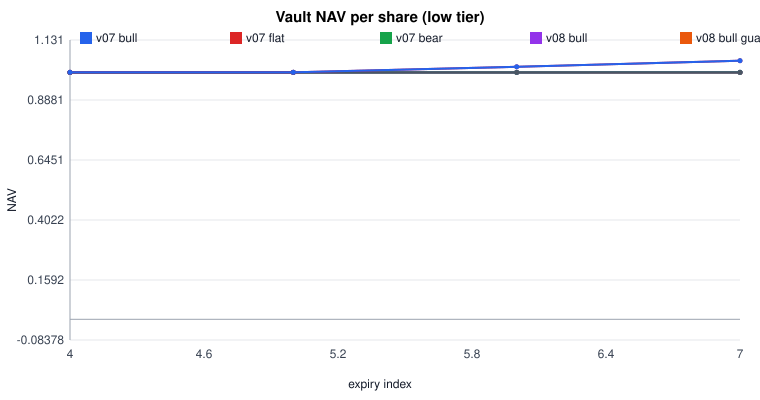

In [2]:
svg("earn_nav_low.svg")  # Low / main tier vault NAV

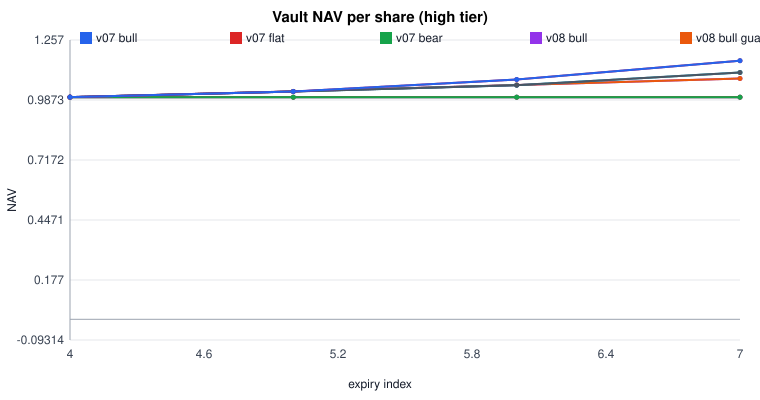

In [3]:
svg("earn_nav_high.svg")  # High tier vault NAV

In [4]:
show(load("earn"), ["rules","path","tier","guard","target_strike","nav_per_share","asset_for_sale_eth","asset_fallback_eth","redeem_queue_len","redeemed_total"], where=lambda r: r["expiry_index"] == "7")

rules | path | tier | guard | target_strike | nav_per_share | asset_for_sale_eth | asset_fallback_eth | redeem_queue_len | redeemed_total
------+------+------+-------+---------------+---------------+--------------------+--------------------+------------------+---------------
  v07 | bull |  low | false |         3,200 |             1 |                  0 |                  0 |                0 |      2,000,000
  v07 | bull | high | false |         3,600 |             1 |                  0 |                  0 |                0 |      2,000,000
  v07 | flat |  low | false |         3,200 |             1 |                  0 |                  0 |                0 |      2,000,000
  v07 | flat | high | false |         3,600 |             1 |                  0 |                  0 |                0 |      2,000,000
  v07 | bear |  low | false |         3,200 |             1 |                  0 |                  0 |                0 |      2,000,000
  v07 | bear | high | false |     

### ❌ APY-threshold buyer (adverse selection)
The threshold never binds in a bull market (nothing to buy below K) and always binds in a bear market: it buys the most exactly when the asset is falling.

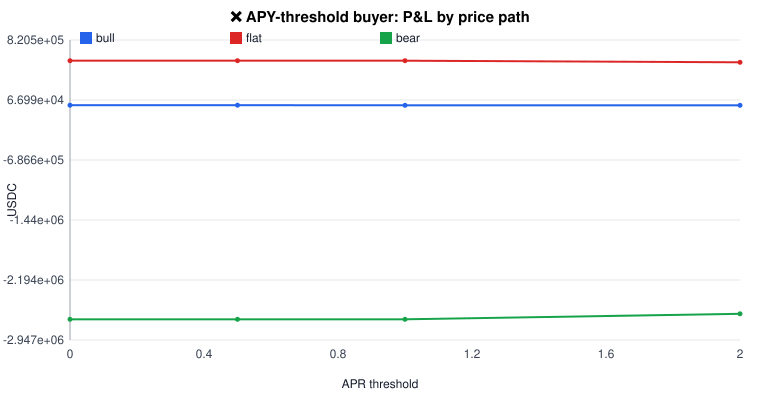

In [5]:
svg("earn_threshold_buyer.svg")  # threshold buyer P&L by path

In [6]:
show(load("earn_threshold_buyer"))

path | apr_threshold | batches_bought | units_bought | avg_price | final_ref_price | defaulted_share | pnl_usdc  
-----+---------------+----------------+--------------+-----------+-----------------+-----------------+-----------
bull |             0 |              6 |           60 |     3,368 |       1.308e+04 |               0 |      1,902
bull |           0.5 |              3 |           30 |     3,352 |       1.308e+04 |               0 |      1,447
bull |             1 |              0 |            0 |         0 |       1.308e+04 |               0 |          0
bull |             2 |              0 |            0 |         0 |       1.308e+04 |               0 |          0
flat |             0 |            328 |        3,280 |     3,229 |           3,419 |               0 |  5.607e+05
flat |           0.5 |            327 |        3,270 |     3,229 |           3,419 |               0 |  5.607e+05
flat |             1 |            327 |        3,270 |     3,229 |           3,419 |    

## Looping (kHYPE/HYPE-style, K = 0.98, sell at 0.97)

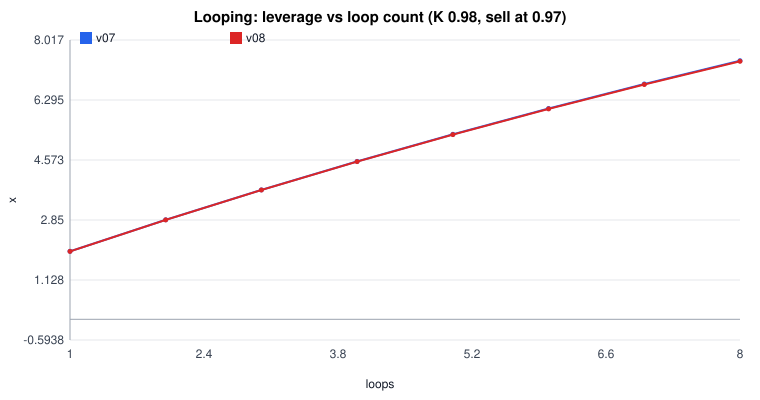

In [7]:
svg("loop_leverage.svg")  # leverage vs loop count

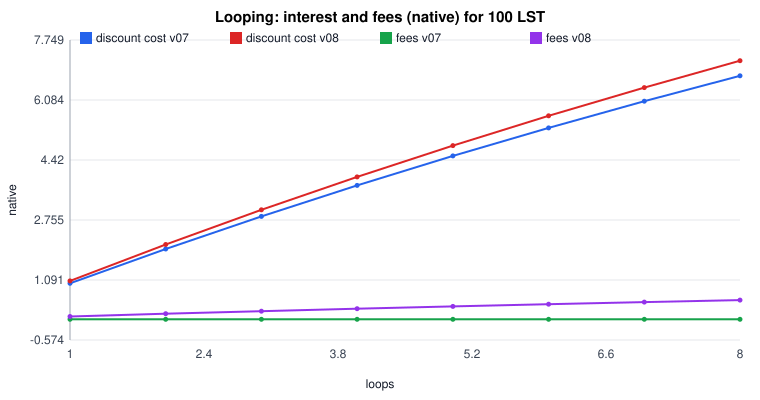

In [8]:
svg("loop_cost.svg")  # interest and fees per 100 LST

In [9]:
show(load("loop"), ["rules","loops","lender_depth_lst","leverage","discount_cost_native","fees_paid_native","breakeven_rate_move_pct","outcome_if_default_native"], where=lambda r: r["lender_depth_lst"] == "500.0")

rules | loops | lender_depth_lst | leverage | discount_cost_native | fees_paid_native | breakeven_rate_move_pct | outcome_if_default_native
------+-------+------------------+----------+----------------------+------------------+-------------------------+--------------------------
  v07 |     1 |              500 |    1.951 |                    1 |                0 |                  0.5025 |                        92
  v07 |     2 |              500 |    2.855 |                1.951 |                0 |                  0.6699 |                     179.5
  v07 |     3 |              500 |    3.715 |                2.855 |                0 |                  0.7535 |                     262.7
  v07 |     4 |              500 |    4.533 |                3.715 |                0 |                  0.8035 |                     341.8
  v07 |     5 |              500 |    5.311 |                4.533 |                0 |                  0.8368 |                     417.1
  v07 |     6 |     

In [10]:
show(load("loop_edges"), ["rules","case","ok","detail"])

rules | case                        | ok   | detail                                                                                            
------+-----------------------------+------+---------------------------------------------------------------------------------------------------
  v07 |               depeg_default | true |                                  LST at 0.95 < K 0.98 at expiry; looper defaults, lender keeps LST
  v07 | partial_repay_before_expiry | true |                                        repaid 142.76720492118415 of 285.5344098423683 LST at day 3
  v07 |          no_quote_to_unwind | true |  repay of 195.0980392156863 LST rejected: insufficient quote: 1 has 1, needs 191196078431372545557
  v07 |    rollover_looped_position | true |   filled in last pre-expiry batch: false; filled in window batch: true; R moved to next pool: true
  v08 |               depeg_default | true |                                  LST at 0.95 < K 0.98 at expiry; looper defaults, lender ke

## Flash loans (real bytecode in revm)

In [11]:
show(load("flashloan"))

case                    | amount_eth | ok    | fee_eth | treasury_pending_eth_after | core_asset_after_eth | gas       | error    
------------------------+------------+-------+---------+----------------------------+----------------------+-----------+----------
             empty_core |          1 | false |       0 |                          0 |                    0 |         0 | flashLoan
    full_balance_repaid |        100 |  true |    0.05 |                       0.05 |                  100 | 1.266e+05 |          
           over_balance |        100 | false |       0 |                       0.05 |                  100 |         0 | flashLoan
full_balance_not_repaid |        100 | false |       0 |                       0.05 |                  100 |         0 | flashLoan
            half_repaid |         50 |  true |   0.025 |                      0.075 |                100.1 | 9.239e+04 |          


## Rollover bridge
v0.7 rollovers only fill inside the window; a 24 h pool has at most one batch boundary in a 2 h window, so most of them default. v0.8 lets the last pre-expiry batch fill them.

In [12]:
from collections import Counter
for (k, v) in sorted(Counter((r["rules"], r["cadence"], r["outcome"]) for r in load("rollover")).items()): print(k, v)

('v07', '0', 'filled_in_window') 18
('v07', '0', 'rejected_insufficient_top_up') 18
('v07', '2', 'defaulted_price_below_min') 12
('v07', '2', 'defaulted_thin_book') 6
('v07', '2', 'rejected_insufficient_top_up') 18
('v08', '0', 'filled_last_pre_expiry_batch') 18
('v08', '0', 'rejected_insufficient_top_up') 18
('v08', '2', 'filled_last_pre_expiry_batch') 18
('v08', '2', 'rejected_insufficient_top_up') 18


## Abandonment auction

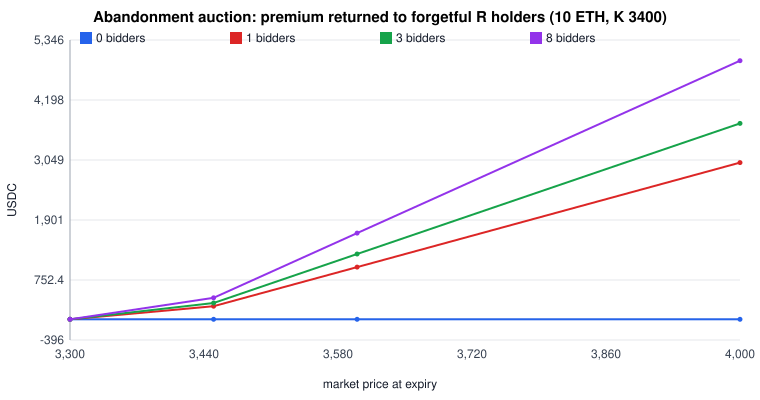

In [13]:
svg("abandonment_recovery.svg")  # premium returned to forgetful R holders

In [14]:
show(load("abandonment"), where=lambda r: r["rules"] == "v08")

rules | unrepaid_eth | market_price | bidders | bid_units_total_eth | units_taken_by_bids_eth | units_defaulted_eth | premium_to_r_holders_usdc | r_holder_recovery_pct_of_residual | bidder_refunds_usdc | c_holder_quote_usdc | c_holder_asset_eth
------+--------------+--------------+---------+---------------------+-------------------------+---------------------+---------------------------+-----------------------------------+---------------------+---------------------+-------------------
  v08 |           10 |        3,300 |       0 |                   0 |                       0 |                  10 |                         0 |                                 0 |                   0 |                  50 |                 10
  v08 |           10 |        3,300 |       1 |                  10 |                      10 |                   0 |                         0 |                                 0 |                   0 |           3.405e+04 |                  0
  v08 |           10